# **Clase 9: Análisis de Datos Cuantitativos**
Variables escalares y de razón



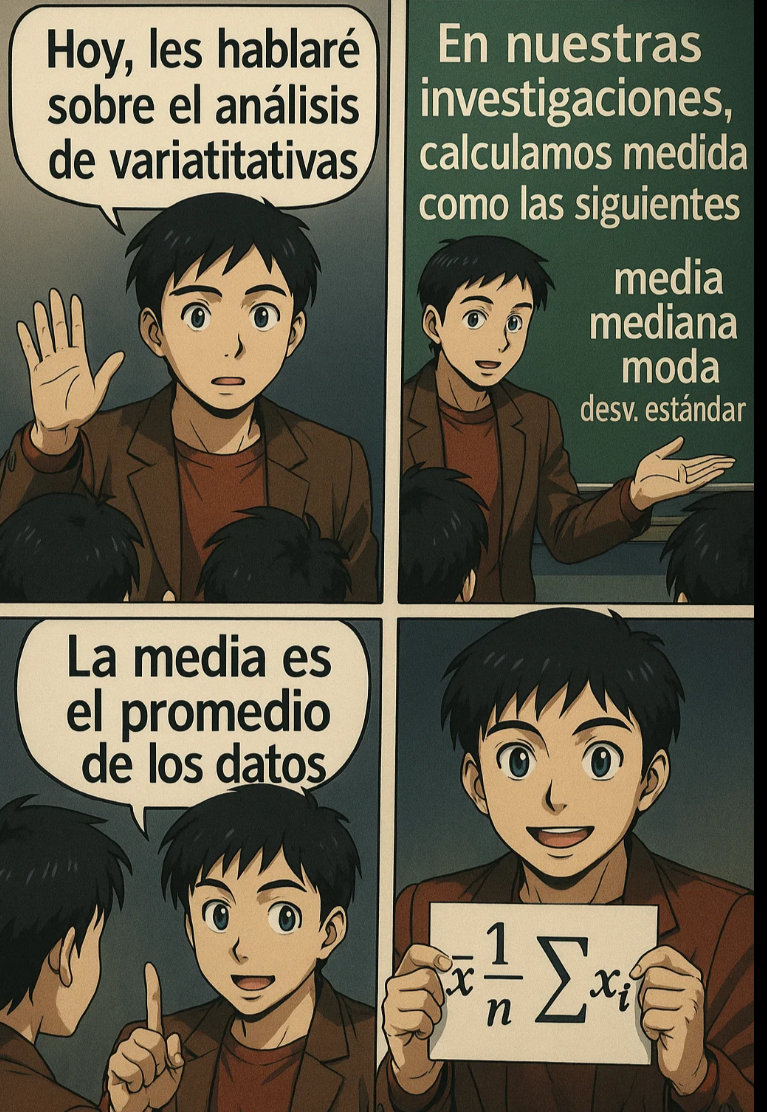

- **Profesor**: Sebastián Matías Muñoz Tapia 👨‍💻
- **Ayudante**: Francesca Rocco 👩🏻‍💻

## 📂 Antes de comenzar

Trabajaremos con **las 185.437 personas de Casen 2020**, conservando solo las cinco variables de esta clase. Descarga [la base pequeña SPSS](https://sebastianmunozt.github.io/metodoscuanti2/clases/clase_09/datos/casen2020_clase9_todos_5variables.sav) y súbela desde **Archivos → Subir al almacenamiento de la sesión**. Si el enlace aún no está publicado, usa el archivo facilitado por el profesor.

Conserva región, comuna, sexo, edad y sueldo líquido del trabajo principal (`y1`). Hay muchos valores ausentes de `y1`: **no significan sueldo cero**. Los ejercicios describen esta base, sin ponderadores; no son estimaciones oficiales de Chile. En grupos pequeños, medias y Gini pueden cambiar bastante. Antes de comparar, revisa cuántos sueldos válidos hay.

In [ ]:
# Solo instalamos los paquetes necesarios que falten.
paquetes <- c("tidyverse", "haven", "DescTools")
faltan <- paquetes[!vapply(paquetes, requireNamespace, logical(1), quietly = TRUE)]
if (length(faltan)) install.packages(faltan, repos = "https://cloud.r-project.org")

In [ ]:
library(tidyverse)
library(DescTools) # Gini() está en este paquete.

In [ ]:
library(haven) # Lee SPSS y conserva sus códigos y etiquetas.

Conecta el entorno **R** y sube `casen2020_clase9_todos_5variables.sav` al panel **Archivos**, sin moverlo a `sample_data`. La celda siguiente busca el archivo en ambas ubicaciones.

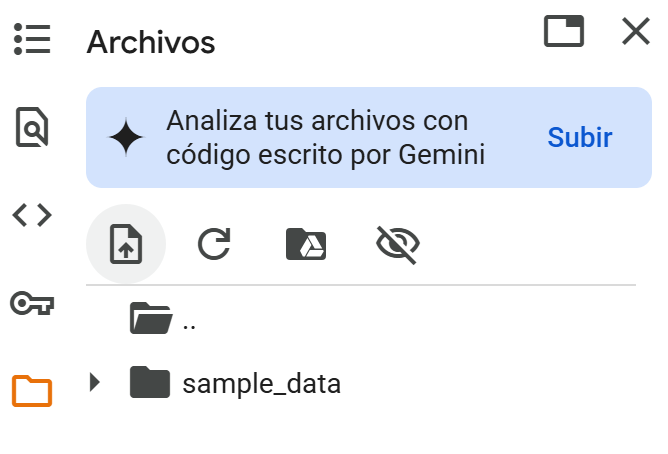

Leemos el SAV con `read_sav()` del paquete `haven`. La región conserva códigos como 13 (Metropolitana) y 5 (Valparaíso); `as_factor()` permite mostrar sus nombres.

In [ ]:
# Busca el archivo en la ubicación habitual de Colab o en sample_data.
rutas <- c("/content/casen2020_clase9_todos_5variables.sav",
           "/content/sample_data/casen2020_clase9_todos_5variables.sav",
           "casen2020_clase9_todos_5variables.sav")
archivo <- rutas[file.exists(rutas)][1]
if (is.na(archivo)) stop("Sube casen2020_clase9_todos_5variables.sav desde el panel Archivos.")
# Convertimos valores perdidos especiales de SPSS a NA, si los hubiera.
datos <- haven::zap_missing(read_sav(archivo, user_na = TRUE))
stopifnot(nrow(datos) == 185437, is.numeric(datos$y1))
cat("Personas:", nrow(datos), "| Sueldos válidos:", sum(!is.na(datos$y1)), "\n")

Veamos si se cargo

In [ ]:
ls()

- Cómo de costumbre hacemos una primera mirada a los datos:

In [ ]:
glimpse(datos)

## 1. Análisis Univariados
### 1.1. Medidas de tendencia central

En primera instancia quiero ver los ingresos de los/as chilenos/as, para eso voy a seleccionar la variable y1: que es el "Sueldo o salario líquido en su trabajo principal", para las personas que recibieron ingreso. En la encuesta hay 40.418. ¿Por qué cree que hay tantos blancos?

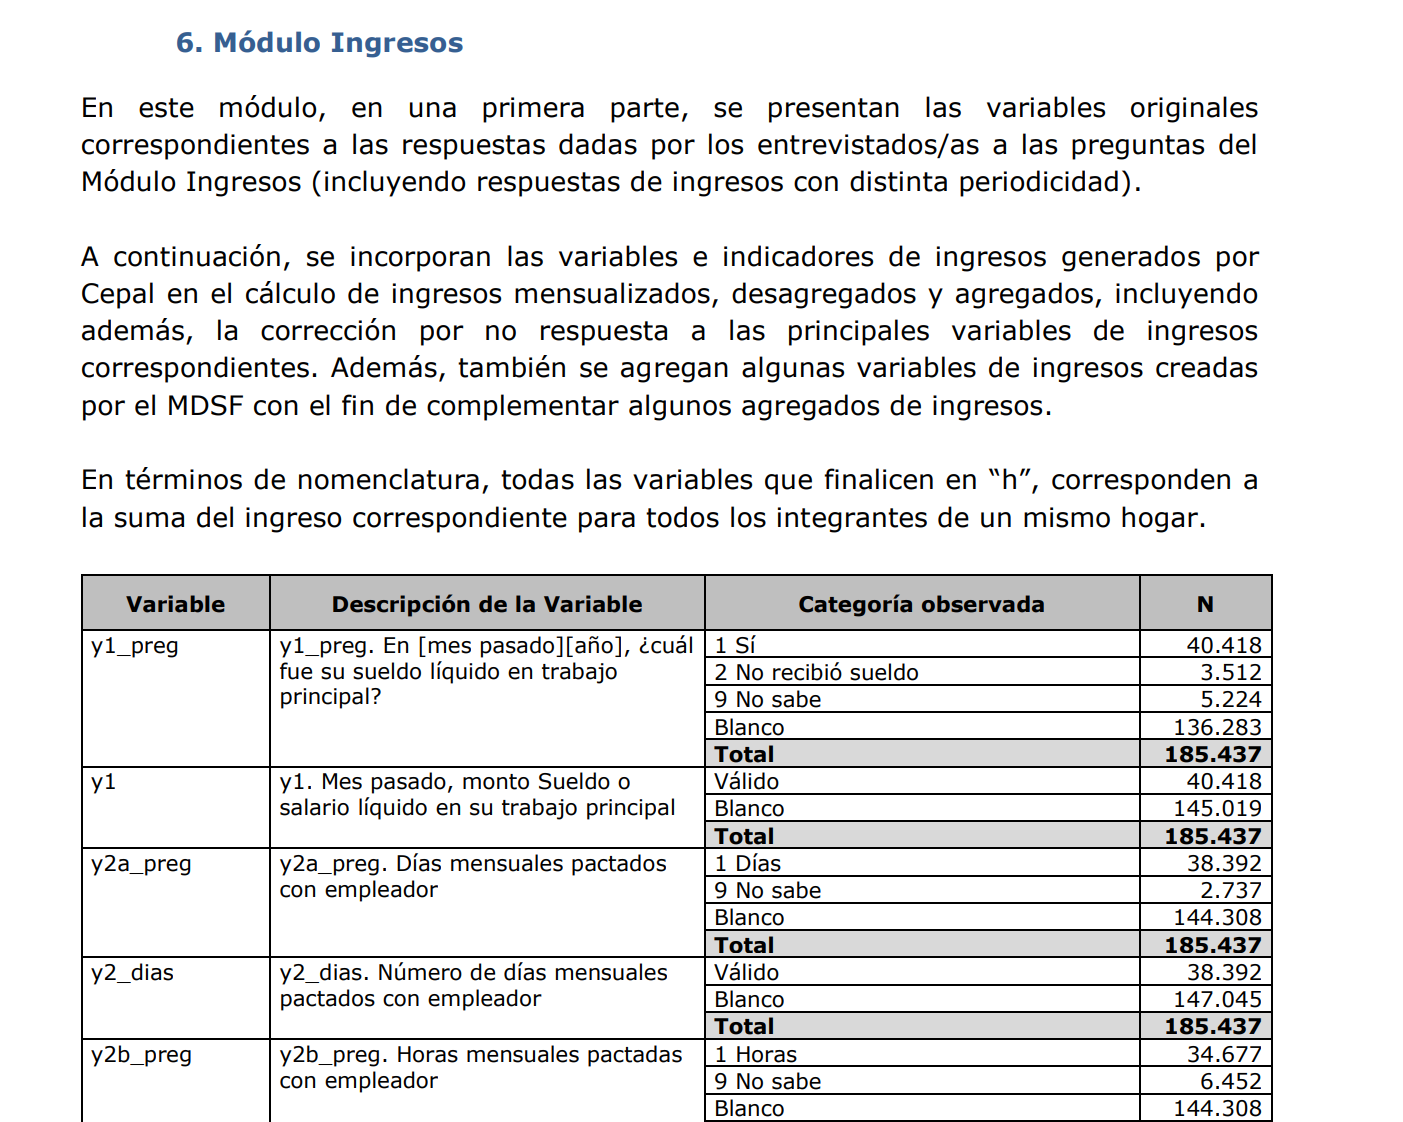

### 1.1.1 Media

In [ ]:
mean(datos$y1)

- Observemos el tipo de variable

In [ ]:
class(datos$y1)

`mean(y1)` devuelve `NA` porque hay valores ausentes. No es un fallo del tipo numérico. Con `na.rm = TRUE` calculamos la media solo entre quienes tienen sueldo registrado.

In [ ]:
mean(datos$y1, na.rm = TRUE)

### Ejercicio

Realice la media de la variable edad.

In [ ]:
mean(datos$edad, na.rm = TRUE)

- Ahora haremos la media en el formato `tidverse`

In [ ]:
datos %>%
  summarise(n_validos = sum(!is.na(y1)), media_y1 = mean(y1, na.rm = TRUE))

# Lo que dice media_y1 es sólo el nombre que va a ir en la tabla

In [ ]:
# Ejercicio: completa los espacios y quita los # para ejecutar.
# datos %>%
#   summarise(media_____ = mean(______, na.rm =_____))

### 1.1.2 Mediana

In [ ]:
median(datos$y1, na.rm = TRUE)

In [ ]:
options(scipen = 999) # para que no me aparezca en notación científica


- Lo haremos con la forma `tidyverse`

In [ ]:
datos %>%
  summarise(n_validos = sum(!is.na(y1)), mediana_y1 = median(y1, na.rm = TRUE))

### Ejercicio

Realicelo para la edad.

In [ ]:
# Ejercicio: completa los espacios y quita los # para ejecutar.
# datos %>%
#   summarise(mediana_edad = ______(______, na.rm = ______))

In [ ]:
datos %>%
  summarise(mediana_edad = median(edad, na.rm = TRUE))

### 1.2. Medidas de dispersión



- Varianza
$$
\sigma^{2} = \frac{1}{N}\sum_{i=1}^{N}\bigl(x_i-\mu\bigr)^2
$$
---

- Desviación estandar
$$
\sigma = \sqrt{\frac{1}{N}\sum_{i=1}^{N}\bigl(x_i-\mu\bigr)^2}
$$

---
- La desvisión estandar es la varianza elevada al cuadrado
$$
\sigma = \sqrt{\sigma^{2}} \qquad\Longleftrightarrow\qquad \sigma^{2} = (\sigma)^2
$$
---

| Símbolo | Nombre | Significado |
|---------|--------|-------------|
| \(\sigma^{2}\) | **Varianza poblacional** | Medida de dispersión promedio al cuadrado respecto a la media. |
| \(N\) | **Tamaño de la población** | Número total de observaciones (datos) en el conjunto. |
| \(\sum_{i=1}^{N}\) | **Sumatoria** | Suma los términos que siguen, desde \(i=1\) hasta \(i=N\). |
| \(x_i\) | **Valor individual** | Observación número \(i\) de la variable. |
| \(\mu\) | **Media poblacional** | Promedio de todos los \(x_i\): \(\mu = \frac{1}{N}\sum_{i=1}^{N} x_i\). |
| \((x_i - \mu)\) | **Desviación** | Diferencia de cada valor frente a la media; puede ser negativa o positiva. |
| \((x_i - \mu)^2\) | **Desviación al cuadrado** | Hace todas las desviaciones no-negativas y penaliza más las alejadas de la media. |
| \(\frac{1}{N}\) | **Promedio** | Divide la suma de desviaciones cuadradas por el número total de datos. |

> **Interpretación:** la varianza es el **promedio de los cuadrados** de las distancias individuales a la media.  
> La **desviación estándar** es su raíz cuadrada: \(\sigma = \sqrt{\sigma^{2}}\).






- ¿Cómo se calcula la **varianza**?
- Hagamos lo paso a paso y luego con una función








In [ ]:
# Paso 1: Calcular la media
media <- mean(datos$y1, na.rm = TRUE)
media

In [ ]:
# Paso 2: Calcular la suma de los cuadrados de las diferencias
sum_cuadrados_dif <- sum((datos$y1 - media)^2, na.rm = TRUE)
sum_cuadrados_dif

In [ ]:
# Paso 3: Dividir la suma de los cuadrados de las diferencias entre n-1
n <- sum(!is.na(datos$y1))
varianza <- sum_cuadrados_dif / (n - 1)


In [ ]:
# Imprimir la varianza
varianza

Ahora lo cáculo con la función `var`

In [ ]:
var <- var(datos$y1, na.rm = TRUE)
var

#vemos que es el mismo resultado

### **Ejercicio**
- Cálcule la varianza de la edad


In [ ]:
# var_edad <- _____(______$_____, na.rm = TRUE)

- ¿Cómo se calcula la **desviación estándar**?

Es la raiz cuadrada de la varianza!

In [ ]:
sqrt(var(datos$y1, na.rm = TRUE))

La desviación estándar del sueldo en esta base es aproximadamente **$709.222**. Resume la dispersión alrededor de la media: no es el error promedio absoluto ni una comparación oficial entre países. La media y la dispersión pueden cambiar al seleccionar otros casos.

In [ ]:
sd(datos$y1, na.rm = TRUE)

### Ejercicio

Realicelo con edad!

### 1.3. Resumir y comparar grupos

Calcularemos media, mediana, desviación estándar, mínimo y máximo de `y1`. Son resultados **sin ponderar de la base de clase**, no de toda la población de Chile.

In [ ]:
datos %>%
  summarise(n_validos = sum(!is.na(y1)), media = mean(y1, na.rm = TRUE),
            mediana = median(y1, na.rm = TRUE),
            desv.est = sd(y1, na.rm = TRUE),
            minimo = if (all(is.na(y1))) NA_real_ else min(y1, na.rm = TRUE), #agrego mínimo
            maximo = if (all(is.na(y1))) NA_real_ else max(y1, na.rm = TRUE)) #agrego máximo

Ahora me gustaría realizarlo con los datos de las comunas de la región metropolitana.

Para eso, primero voy a ver las variables de mi base y luego voy a ver las categorias de la variable región.

In [ ]:
names(datos)
unique(datos$region)

- Ahora quiero hacer una tabla para todas las comunas de la región metropolitana y utilizo la función `group_by()`



In [ ]:
datos %>%
  filter(region == 13) %>%                      # 13 = Región Metropolitana
  mutate(comuna = as_factor(comuna)) %>%        # pasa códigos → nombres
  group_by(comuna) %>%
  summarise(n_validos = sum(!is.na(y1)), 
    media    = mean(y1, na.rm = TRUE),
    mediana  = median(y1, na.rm = TRUE),
    desv.est = sd(y1, na.rm = TRUE)
  )

Hago lo mismo pero ahora lo ordeno por la media

In [ ]:
ingresos_por_comuna_media <- datos %>%
  filter(region == 13) %>%                     # 13 = Región Metropolitana
  mutate(comuna = as_factor(comuna)) %>%       # códigos → nombres
  group_by(comuna) %>%
  summarise(n_validos = sum(!is.na(y1)), 
    media    = mean(y1, na.rm = TRUE),
    mediana  = median(y1, na.rm = TRUE),
    desv.est = sd(y1, na.rm = TRUE)
  ) %>%
  arrange(desc(media))

  ingresos_por_comuna_media

- Ahora lo ordeno por la mediana

In [ ]:
ingresos_por_comuna_mediana <- datos %>%
  filter(region == 13) %>%              # 13 = Región Metropolitana
  mutate(comuna = as_factor(comuna)) %>%# convierte códigos → nombres
  group_by(comuna) %>%
  summarise(n_validos = sum(!is.na(y1)), 
    media    = mean(y1, na.rm = TRUE),
    mediana  = median(y1, na.rm = TRUE),
    desv.est = sd(y1, na.rm = TRUE)
  ) %>%
  arrange(desc(mediana))
  ingresos_por_comuna_mediana

- Ahora lo ordeno según el desvio estándar

In [ ]:
ingresos_por_desvio <- datos %>%
  filter(region == 13) %>%               # 13 = Región Metropolitana
  mutate(comuna = as_factor(comuna)) %>% # códigos → nombres
  group_by(comuna) %>%
  summarise(n_validos = sum(!is.na(y1)), 
    media    = mean(y1, na.rm = TRUE),
    mediana  = median(y1, na.rm = TRUE),
    desv.est = sd(y1, na.rm = TRUE)
  ) %>%
  arrange(desc(desv.est))
  ingresos_por_desvio



In [ ]:
ingresos_por_media_minmax <- datos %>%
  filter(region == 13) %>%                # 13 = Región Metropolitana
  mutate(comuna = as_factor(comuna)) %>%  # códigos → nombres de comuna
  group_by(comuna) %>%
  summarise(n_validos = sum(!is.na(y1)), 
    media    = mean(y1, na.rm = TRUE),
    mediana  = median(y1, na.rm = TRUE),
    desv.est = sd(y1, na.rm = TRUE),
    minimo   = if (all(is.na(y1))) NA_real_ else min(y1, na.rm = TRUE),     # valor mínimo
    maximo   = if (all(is.na(y1))) NA_real_ else max(y1, na.rm = TRUE)      # valor máximo
  ) %>%
  arrange(desc(media))                    # ordenar por la media

  ingresos_por_media_minmax


### Ejercicio
Realicé una tabla de ingreso `y1` considerando la media (mean), mediana(median), desviación estandart(sd) por comuna, para la región de Valparaiso.

### 1.3.1. Cuartiles, deciles y percentiles


In [ ]:
datos %>%
  summarise(n_validos = sum(!is.na(y1)), media = mean(y1, na.rm = TRUE),
            mediana = median(y1, na.rm = TRUE),
            desv.est = sd(y1, na.rm = TRUE),
            minimo = if (all(is.na(y1))) NA_real_ else min(y1, na.rm = TRUE),
            maximo = if (all(is.na(y1))) NA_real_ else max(y1, na.rm = TRUE),
            cuartil_1 = quantile(y1, probs = 0.25, na.rm = TRUE),
            cuartil_2 = quantile(y1, probs = 0.50, na.rm = TRUE),
            cuartil_3 = quantile(y1, probs = 0.75, na.rm = TRUE),
            decil_rico = quantile(y1, probs = 0.99, na.rm = TRUE)) %>%
  arrange(desc(media))

| Argumento | Qué hace                                       | Detalles clave                                                                                                                                                                                                                                                     |
| --------- | ---------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| `x`       | Vector numérico                                | No puede ser factor ni carácter; si está agrupado con `dplyr`, se evalúa dentro de cada grupo.                                                                                                                                                                     |
| `probs`   | Vector numérico con probabilidades entre 0 y 1 | Controla **qué** cuantiles se devuelven. <br>- `0.25` → primer cuartil (25 % inferior).<br>- `0.50` → mediana (50 %).<br>- `0.75` → tercer cuartil (75 %).<br>- Se pueden pasar varios valores a la vez: `probs = c(.10, .90)` devolverá el 10.º y 90.º percentil. |
| `na.rm`   | Lógico (`FALSE` por defecto)                   | `TRUE` → elimina los `NA` antes del cálculo. <br>`FALSE` → si hay al menos un `NA`, el resultado es `NA`.                                                                                                                                                          |


### Explicación de `quantile()` en R 🤔

La función `quantile()` devuelve los puntos de corte que dividen una distribución numérica de acuerdo con las probabilidades definidas en el argumento `probs`.  Dicho argumento se expresa siempre con valores entre 0 y 1.  Si, por ejemplo, se indica `probs = 0.25`, el resultado es el primer cuartil, es decir, el valor por debajo del cual se sitúa el 25 % de las observaciones; con `probs = 0.50` se obtiene la mediana y con `probs = 0.99` el percentil 99.

Un segundo argumento clave es `na.rm`.  Al establecerlo en `TRUE`, R ignora las observaciones perdidas (`NA`) antes de calcular los cuantiles; si se deja en el valor por defecto (`FALSE`), basta un solo `NA` en el vector para que el resultado completo se convierta también en `NA`.

En el ejemplo que presentas, cada llamada a `quantile()` dentro de `summarise()` crea una columna nueva.  De esta manera, `quantile(y1, probs = 0.25, na.rm = TRUE)` guarda el primer cuartil en `cuartil_1`; `probs = 0.50` produce de nuevo la mediana—útil cuando quieres mantener la nomenclatura de “cuartil 2”—y `probs = 0.75` y `0.99` capturan respectivamente el tercer cuartil y el valor por encima del cual se encuentra solo el 1 % con mayores ingresos.  Como todos los estadísticos se calculan con `na.rm = TRUE`, los valores faltantes se descartan y no interfieren en ningún resultado.

### 1.3.2. Coeficiente Gini

In [ ]:
Gini(datos$y1, na.rm = TRUE)

In [ ]:
datos %>%
  mutate(region = as_factor(region)) %>%      # 13 → “Región Metropolitana”, etc.
  group_by(region) %>%                       # ahora agrupa por el nombre
  summarise(n_validos = sum(!is.na(y1)), 
    coeficiente_gini = Gini(y1, na.rm = TRUE),
    media            = mean(y1, na.rm = TRUE)
  ) %>%
  arrange(desc(coeficiente_gini))             # de mayor a menor

El **Gini** resume desigualdad: cero corresponde a igualdad de valores y valores próximos a uno indican mayor concentración. No hay cortes universales para clasificarlo como bajo o alto. Aquí describe sueldos válidos de una submuestra, no la desigualdad total de ingresos de Chile. Los extremos y los grupos con pocos casos pueden cambiar mucho el resultado.

### Ejercicio

Seleccione la región metropolitana y vea la desiguladad por comuna.

In [ ]:
# Ejercicio: completa los espacios y quita los # para ejecutar.
# datos %>%
#   filter(region == _______) %>%
#   mutate(________ = as_factor(_______)) %>%
#   group_by(________) %>%
#   summarise(n_validos = sum(!is.na(y1)), 
#     coeficiente_gini = Gini(y1, na.rm = TRUE),
#     media            = mean(y1, na.rm = TRUE)
#   ) %>%
#   arrange(desc(coeficiente_gini))

## **2. Gráficos univariados de variables cuantitativas**
### 2.1. Gráfico de "caja y bigote" o `geom_boxplot()` 👨

- Vamos con un primer gráfico, que se llama de caja y bigotes.
- Iremos refinando y explicando como entenderlo

In [ ]:
ggplot(datos, aes(y = y1, x ="")) +
  geom_boxplot()


Un diagrama de caja muestra la **mediana** (línea interior), el primer y tercer cuartil (bordes de la caja) y valores alejados que quedan fuera de los bigotes. **No muestra la media por defecto.** Los bigotes llegan al valor observado más extremo dentro de 1,5 veces la distancia entre cuartiles; no necesariamente al mínimo y máximo.

In [ ]:
datos %>%
  summarise(n_validos = sum(!is.na(y1)), mediana = median(y1, na.rm = TRUE),
            desv.est = sd(y1, na.rm = TRUE),
            minimo = if (all(is.na(y1))) NA_real_ else min(y1, na.rm = TRUE),
            maximo = if (all(is.na(y1))) NA_real_ else max(y1, na.rm = TRUE),
            cuartil_1 = quantile(y1, probs = 0.25, na.rm = TRUE),
            cuartil_2 = quantile(y1, probs = 0.50, na.rm = TRUE),
            cuartil_3 = quantile(y1, probs = 0.75, na.rm = TRUE))

Ahora acercamos la vista hasta el percentil 95 sin eliminar observaciones antes de calcular la caja. `coord_cartesian()` cambia la ventana visible; `outlier.shape = NA` solo oculta puntos, no los borra.

In [ ]:
ggplot(datos, aes(y = y1, x= "")) +
  geom_boxplot(outlier.shape = NA, coef = 1.5, width = 0.6) +
  coord_cartesian(ylim = c(0, quantile(datos$y1, 0.95, na.rm = TRUE))) + # acercamos la vista sin borrar casos
  theme_classic()

`coord_cartesian(ylim = ...)` permite acercar la vista manteniendo los cuartiles de todos los sueldos válidos. La ausencia de un punto en la ventana no significa que lo hayamos borrado de la base.

Ahora vamos a darle color, mediante fill="tomato"

In [ ]:
ggplot(datos, aes(y = y1, x="")) +
  geom_boxplot(outlier.shape = NA, coef = 1.5, width = 0.6,  fill= "tomato") +
  coord_cartesian(ylim = c(0, quantile(datos$y1, 0.95, na.rm = TRUE))) +
  theme_minimal()+
  ylab("Ingresos")

Ahora podré poner en x, una variable. Por ejemplo el sexo y cambio el color también por esa variable.
* En google colab, parece ser necesario indicarle explicitamente cuáles son las variables tipo factor. Sino, las toma como numéricas.

In [ ]:
ggplot(datos, aes(x = as.factor(sexo),
                  y = y1,
                  fill = as.factor(sexo),
                  group = as.factor(sexo))) +
  geom_boxplot(outlier.shape = NA, coef = 1.5, width = 0.6) +
  coord_cartesian(ylim = c(0, quantile(datos$y1, 0.95, na.rm = TRUE))) +
  guides(fill = "none") +
  theme_minimal()


In [ ]:
ggplot(
  datos %>% mutate(sexo = as_factor(sexo)),       # convierte 'sexo' a factor
  aes(x = sexo, y = y1, fill = sexo)
) +
  stat_boxplot(
    geom  = "errorbar",
    width = 0.15,
    coef  = 1.5,
    color = 1
  ) +
  geom_boxplot(
    width          = 0.6,
    fill           = 2,        # rojo
    alpha          = 0.5,
    color          = 1,        # borde negro
    outlier.colour = 2,
    outlier.shape  = 19,
    outlier.size   = 2
  ) +
  coord_cartesian(ylim = c(0, quantile(datos$y1, 0.95, na.rm = TRUE))) +
  labs(y = "Ingresos") +       # etiqueta del eje Y
  guides(fill = "none") +
  theme_minimal()


### Ejercicio
- Realiza los siguiente cálculos para la edad de toda la población: mediana, mínimo, máximo, cuartil 1, 2 y 3.

In [ ]:
# Ejercicio: completa los espacios y quita los # para ejecutar.
# datos %>%
#   summarise(mediana = _____(____, na.rm = TRUE),
#             desv.est = ____(____, na.rm = TRUE),
#             minimo = ____(____, na.rm = TRUE),
#             maximo = ____(____, na.rm = TRUE),
#             cuartil_1 = quantile(____, probs = _____, na.rm = TRUE),
#             cuartil_2 = quantile(____, probs = _____, na.rm = TRUE),
#             cuartil_3 = quantile(____, probs = _____, na.rm = TRUE))

- Realiza un gráfico de caja y bigote para edad, sin sacar los extremos

In [ ]:
# Ejercicio: completa los espacios y quita los # para ejecutar.
# ggplot(datos, aes(y = _____)) +
#   geom_boxplot()

- Realiza un gráfico de caja y bigotes para edad dividido por sexo, sin sacar los extremos

In [ ]:
# Ejercicio: completa los espacios y quita los # para ejecutar.
# ggplot(datos, aes(y =______, x = as.factor(_____))) +
#   geom_boxplot()

- Ahora vamos a realizar un gráfico "elegante" para edad distinguido por sexo, modificando lo que tenga que modificar

In [ ]:
ggplot(
  datos %>%
    mutate(
      sexo = factor(sexo,
                    levels = c(1, 2),
                    labels = c("Hombre", "Mujer"))
    ),
  aes(x = sexo, y = edad, fill = sexo)
) +
  stat_boxplot(
    geom  = "errorbar",
    width = 0.15,
    coef  = 1.5,
    color = "black"
  ) +
  geom_boxplot(
    width          = 0.6,
    alpha          = 0.6,
    color          = "black",
    outlier.colour = "black",
    outlier.shape  = 19,
    outlier.size   = 2
  ) +
  # paleta neutra y legible (viridis)
  scale_fill_viridis_d(option = "C", end = 0.8) +
  labs(
    x    = "Sexo",
    y    = "Edad",
    fill = "Sexo"
  ) +
  theme_minimal()


### 2.2. Gráfico Histograma o `geom_histogram()`



In [ ]:
ggplot(datos, aes(x = y1)) +
  geom_histogram(binwidth = 100000, color = "black", fill = "gray") + #binwidth: hacer rangos de 100.000
  labs(x = "Ingresos", y = "Frecuencia") +
  theme_classic()

Un **histograma** es una forma sencilla de responder dos preguntas básicas sobre tus datos:

1. **¿Qué rangos de valores existen?**  
2. **¿Cuántos casos caen dentro de cada rango?**

Imagina que tienes todos los ingresos de tu encuesta y los ordenas. En vez de mirar cada sueldo uno por uno, los agrupas en “cajitas” de igual tamaño:

| Paso | Qué sucede |
|------|------------|
| **Definir el ancho de la cajita** | En el código se usa `binwidth = 100000`, es decir, cada cajita abarca \$100 000 de ingreso. |
| **Contar dentro de cada cajita** | Para cada rango sumas cuántas personas ganan dentro de él. |
| **Dibujar barras** | A cada cajita le corresponde una barra: la base indica el rango y la altura muestra la cantidad de personas. |

Así, el histograma muestra de un vistazo:

- **Dónde se concentra la mayoría**: las barras más altas indican los rangos de ingreso más comunes.  
- **Si hay valores extremos**: barras solitarias en los extremos señalan personas que ganan mucho más o mucho menos que el resto.  
- **La forma de la distribución**: ¿es simétrica, está “cargada” a la izquierda o a la derecha, presenta varios picos?

#### Relación con el código

```r
ggplot(datos, aes(x = y1)) +
  geom_histogram(binwidth = 100000, color = "black", fill = "gray") +
  labs(x = "Ingresos", y = "Frecuencia") +
  theme_classic()
```

- **`aes(x = y1)`**: usa la columna **`y1`** (ingresos) en el eje horizontal.  
- **`geom_histogram(binwidth = 100000)`**: crea cajitas de \$100 000 y dibuja cada barra.  
- **`labs()`**: asigna nombres claros a los ejes (“Ingresos” y “Frecuencia”).  
- **`theme_classic()`**: aplica un estilo limpio sin fondo gris.

---

### **¿Por qué creen que no se ve tan bien?** 😭





In [ ]:
ggplot(datos, aes(x = y1)) +
  geom_histogram(binwidth = 200000, color = "black", fill = "gray") + #binwidth:hago rangos de 200.000
  labs(x = "Ingresos", y = "Frecuencia") +
  theme_classic()

Acercamos la vista hasta el percentil 99; la base conserva los valores más altos. Calculamos el mínimo con `na.rm = TRUE` para que los ausentes no impidan fijar el límite.

In [ ]:
ggplot(datos, aes(x = y1)) +
  geom_histogram(binwidth = 100000, color = "black", fill = "gray") +
  coord_cartesian(xlim = c(min(datos$y1, na.rm = TRUE), quantile(datos$y1, 0.99, na.rm = TRUE))) + # acercamos la vista
  labs(x = "Ingresos", y = "Frecuencia") +
  theme_classic()

Construimos una pirámide con los **casos de esta base**, por edad y sexo. El tamaño absoluto de las barras será menor que en la base completa; para comparar las formas entre bases se usan porcentajes.

In [ ]:
datos %>%
  drop_na(edad, sexo) %>%                            # descarta registros sin edad o sexo
  mutate(
    sexo = factor(sexo, levels = c(1, 2),
                  labels = c("Hombre", "Mujer")),

    # añade un tramo explícito para ≥ 90 años y evita que quede NA
    edad_tramo = cut(
      edad,
      breaks  = c(seq(0, 90, 5), Inf),               # 0-4, 5-9, …, 85-89, 90+
      right   = FALSE,
      labels  = c(paste(seq(0, 85, 5),
                        seq(4, 89, 5), sep = "–"),
                  "90+")
    )
  ) %>%
  count(edad_tramo, sexo, name = "n") %>%            # conteo por grupo
  mutate(
    n = case_when(sexo == "Hombre" ~ -n,             # hombres a la izquierda
                  TRUE              ~  n)
  ) %>%
  ggplot(aes(x = edad_tramo, y = n, fill = sexo)) +
  geom_col(width = 0.9) +
  coord_flip() +
  scale_y_continuous(
    breaks = scales::pretty_breaks(),
    labels = abs
  ) +
  scale_fill_manual(
    values = c("Hombre" = "#3B7F92",
               "Mujer"  = "#CC984A")
  ) +
  labs(
    x    = "Grupo de edad (años)",
    y    = "Población",
    fill = "Sexo"
  ) +
  theme_minimal()

| Rasgo visible                                                          | Interpretación                                                                                                                                                                                     |
| ---------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Base más estrecha que el bloque central (0–14 años vs. 20–34 años)** | La natalidad ya **viene bajando desde mediados de los 2000**: las cohortes infantiles son sensiblemente menores que las nacidas en los 90 y principios de los 2000.                                |
| **Mayor amplitud entre 20–34 años**                                    | Esa “joroba” corresponde a la **generación nacida durante el último período de alta fecundidad**; hoy es la principal fuerza laboral y explicará un “bono demográfico” que todavía dura unos años. |
| **Descenso gradual a partir de 35 años, pero sin vacíos bruscos**      | Refleja décadas sin guerras ni crisis migratorias masivas que pudieran “cortar” cohortes completas; la transición demográfica chilena ha sido relativamente estable.                               |
| **Proporción creciente de mujeres desde \~60 años**                    | La **mayor esperanza de vida femenina** se evidencia: a partir de los 60 la barra dorada supera a la azul y la diferencia se agranda con la edad.                                                  |
| **Tramo 80+ todavía delgado, pero visible**                            | Chile está **envejeciendo**; aunque el grupo ≥ 80 años es pequeño, su presencia sostenida indica mejoras en supervivencia y plantea futuros desafíos sanitarios y previsionales.                   |


**Para interpretar**

Identifica los tramos con más y menos casos en esta base. ¿La forma es parecida entre hombres y mujeres? Un solo gráfico sin ponderadores no permite establecer por sí solo una etapa demográfica ni explicar por qué hay más o menos casos en cada tramo.

¿